# Estimate a conditional quantile and quantify its uncertainty

A conditional quantile, its estimation uncertainty and a future response are three different targets. We use one simulated regression dataset to show them side by side: `QuantileGAM` estimates a median, `CalibratedQuantileGAM` calibrates uncertainty about a median function, and split conformal prediction supplies a future-response interval.

The data have a known linear conditional median and Gaussian noise. The spline fits are allowed modest flexibility. The purpose is to distinguish targets, not to claim that one interval method substitutes for another.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


from nampy import QuantileGAM, CalibratedQuantileGAM
from nampy.calibration import calibrate_regressor


In [2]:
def show_figure(figure, name):
    # name is a stable identifier for the corresponding guide figure.
    plt.show()
    plt.close(figure)

In [3]:
rng = np.random.default_rng(82)
X = pd.DataFrame({"x": rng.uniform(-1.5, 1.5, 600)})
y = 0.4 + 0.8 * X.x.to_numpy() + rng.normal(0, 0.65, len(X))
order = rng.permutation(len(X))
train, calibration, test = order[:300], order[300:450], order[450:]
formula = "~s(x,k=5)"

## Fit the median and its calibrated inference model

The 600 independent rows are split into 300 training, 150 calibration and 150 test rows. Both median fits use only the training cohort. `level=0.5` specifies the response quantile, not confidence coverage.

`QuantileGAM` here uses a positive ELF bandwidth and a declared coefficient tolerance of 1e-7; it provides a point estimate without calibrated coefficient intervals. `CalibratedQuantileGAM` also uses a fixed bandwidth and fixed smoothing but selects its scalar loss scale by the calFast criterion. Its `predict_interval(..., level=0.95)` instead specifies confidence in the estimated median function.

In [4]:
quantile = QuantileGAM(
    formula=formula, level=0.5, smoothing_params=[0.5], bandwidth=0.2, tol=1e-7
).fit(X.iloc[train], y[train])
assert quantile.fit_result_.converged
calibrated = CalibratedQuantileGAM(
    formula=formula, level=0.5, bandwidth=0.2, smoothing_params=[0.5],
    log_scale_bounds=(-4, 2),
).fit(X.iloc[train], y[train])

## Calibrate future-response intervals on separate rows

The conformal step receives the already fitted `QuantileGAM` and the 150 calibration outcomes. It does not change the fitted median. Absolute residual scores calibrate a 90% response interval under exchangeability of calibration and future rows.

The 150 test outcomes are reserved for the final empirical coverage assessment. They neither fit the regression models nor select the conformal threshold.

In [5]:
# This separate cohort calibrates future-response coverage; it does not
# train either quantile model or calibrate its coefficient uncertainty.
response = calibrate_regressor(
    quantile, X.iloc[calibration], y[calibration], level=0.9
)
grid = pd.DataFrame({"x": np.linspace(-1.5, 1.5, 160)})
confidence = calibrated.predict_interval(grid, level=0.95)
future = response.predict_interval(grid)
test_interval = response.predict_interval(X.iloc[test])
coverage = np.mean((y[test] >= test_interval.lower) & (y[test] <= test_interval.upper))

## Compare the targets visually

The mean width of the 95% pointwise median-function interval is about 0.30; the 90% future-response interval is about 2.08 wide. Their different widths reflect different targets and cannot be read as a competition between coverage levels.

Most future observations need not fall in the median confidence band. Its target is the unknown conditional median, while conformal coverage targets a future noisy response marginally over the feature distribution.

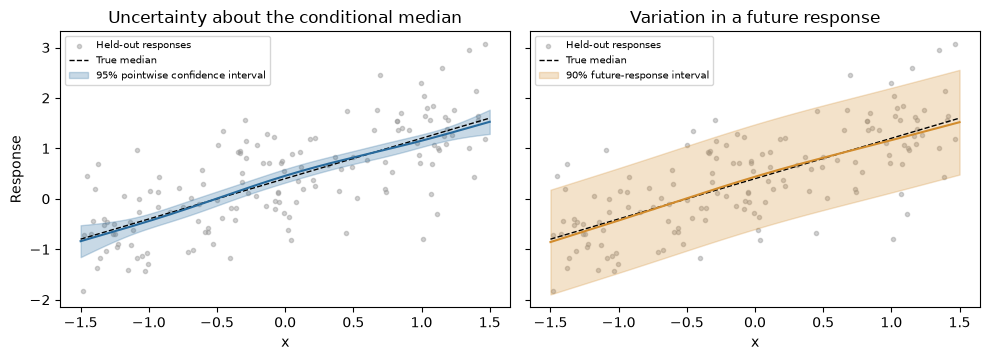

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.7), sharey=True)
for axis in axes:
    axis.scatter(X.x.iloc[test], y[test], s=9, color="0.6", alpha=0.45,
                 label="Held-out responses")
    axis.plot(grid.x, 0.4 + 0.8 * grid.x, "k--", lw=1, label="True median")
axes[0].fill_between(grid.x, confidence.lower, confidence.upper,
                     color="#276A9D", alpha=0.25, label="95% pointwise confidence interval")
axes[0].plot(grid.x, confidence.estimate, color="#276A9D")
axes[1].fill_between(grid.x, future.lower, future.upper, color="#D28C2D",
                     alpha=0.25, label="90% future-response interval")
axes[1].plot(grid.x, quantile.predict(grid), color="#D28C2D")
axes[0].set(title="Uncertainty about the conditional median", xlabel="x", ylabel="Response")
axes[1].set(title="Variation in a future response", xlabel="x")
for axis in axes:
    axis.legend(fontsize=7, loc="upper left")
figure.tight_layout()
show_figure(figure, "quantile_targets")

## Check what conformal calibration changed

For a visible before/after comparison, a deliberately uncalibrated ±0.5 response band is shown alongside conformal bounds. The narrow band covers about 55% of independent test responses, while the 90% conformal interval covers 88% in this finite test sample. The calibrated band is wider; coverage improvement has a measurable width cost.

The ±0.5 band has no inferential coverage claim. One held-out coverage proportion may fall below or above its target, and does not establish conditional coverage for every x.

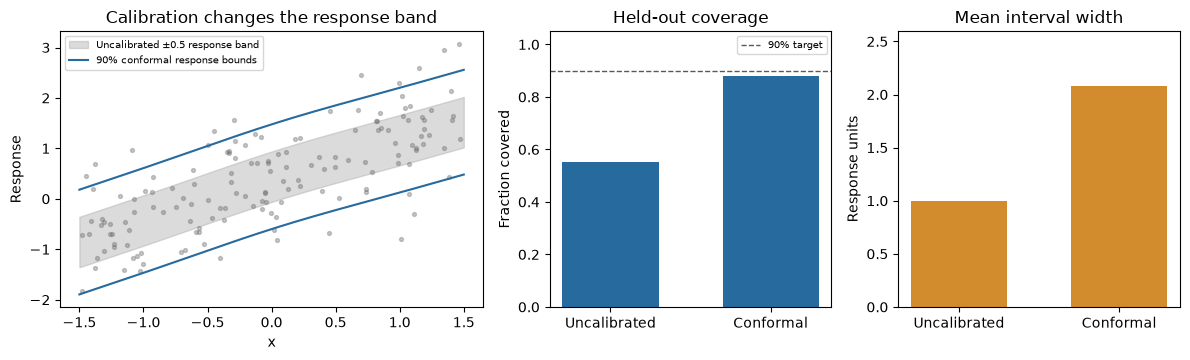

Median-function pointwise CI mean width: 0.304.
90% conformal response interval: test coverage 88.0%; mean width 2.076.
Uncalibrated response band: test coverage 55.3%; width 1.0.


In [7]:
# A deliberately narrow, uncalibrated response band has no coverage claim.
# Report both its width and independent-test coverage beside conformal's.
before = quantile.predict(X.iloc[test])
baseline_coverage = np.mean(np.abs(y[test] - before) <= 0.5)
widths = [1.0, float(np.mean(test_interval.upper - test_interval.lower))]
figure, axes = plt.subplots(
    1, 3, figsize=(12, 3.7), gridspec_kw={"width_ratios": [1.5, 1, 1]}
)
axes[0].fill_between(grid.x, quantile.predict(grid) - 0.5,
                     quantile.predict(grid) + 0.5, color="0.65", alpha=0.4,
                     label="Uncalibrated ±0.5 response band")
axes[0].plot(grid.x, future.lower, color="#276A9D", label="90% conformal response bounds")
axes[0].plot(grid.x, future.upper, color="#276A9D")
axes[0].scatter(X.x.iloc[test], y[test], s=8, color="0.4", alpha=0.35)
axes[0].set(xlabel="x", ylabel="Response", title="Calibration changes the response band")
axes[0].legend(fontsize=7)
positions = np.arange(2)
labels = ["Uncalibrated", "Conformal"]
axes[1].bar(positions, [baseline_coverage, coverage], color="#276A9D", width=0.6)
axes[1].axhline(0.9, color="0.35", ls="--", lw=1, label="90% target")
axes[1].set(xticks=positions, xticklabels=labels, ylabel="Fraction covered",
            ylim=(0, 1.05), title="Held-out coverage")
axes[1].legend(fontsize=7)
axes[2].bar(positions, widths, color="#D28C2D", width=0.6)
axes[2].set(xticks=positions, xticklabels=labels, ylabel="Response units",
            ylim=(0, max(widths) * 1.25), title="Mean interval width")
figure.tight_layout()
show_figure(figure, "conformal_intervals")
print(f"Median-function pointwise CI mean width: {np.mean(confidence.upper-confidence.lower):.3f}.")
print(f"90% conformal response interval: test coverage {coverage:.1%}; mean width {widths[1]:.3f}.")
print(f"Uncalibrated response band: test coverage {baseline_coverage:.1%}; width {widths[0]:.1f}.")

## Choose the target before the API

Use a quantile estimator for a conditional percentile, a calibrated quantile-function interval for uncertainty about that percentile, and a conformal interval for a future response. This run fixes smoothing; when automatic smoothing is selected, quantile-function intervals explicitly condition on the selected penalties. See [quantile inference](../user_guide/quantile_inference.rst) and [conformal calibration](../user_guide/calibration.rst) for the distinct assumptions and metadata.